### Data Import

In [2]:
from pathlib import Path
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer


In [3]:
project_root = Path().resolve()
data_path = Path(project_root/ "data"/ "df_final.csv")

df_train = pd.read_csv(data_path)

In [4]:
data_path2 = Path(project_root/ "data"/ "df_test.csv")

df_test = pd.read_csv(data_path2)

In [5]:
# Quick NaN check on train/test
print("NaN counts (train):")
print(df_train.isna().sum().sort_values(ascending=False).head(10))
print("\nNaN counts (test):")
print(df_test.isna().sum().sort_values(ascending=False).head(10))

NaN counts (train):
tranche_effectif_ord                    0
resume_tfidf_1                          0
operateur_type_None                     0
operateur_type_Water_agency             0
demarche_Dechets_economie_circulaire    0
demarche_Developpement_economique       0
demarche_Eau                            0
demarche_Energie                        0
demarche_Ingenierie                     0
demarche_Missing                        0
dtype: int64

NaN counts (test):
tranche_effectif_ord                    0
resume_tfidf_1                          0
operateur_type_None                     0
operateur_type_Water_agency             0
demarche_Dechets_economie_circulaire    0
demarche_Developpement_economique       0
demarche_Eau                            0
demarche_Energie                        0
demarche_Ingenierie                     0
demarche_Missing                        0
dtype: int64


In [6]:
X_train = df_train.drop('montant_engage', axis=1)
y_train = df_train['montant_engage']
X_test = df_test.drop('montant_engage', axis=1)
y_test = df_test['montant_engage']

In [7]:
# Align train/test feature columns to the common set
train_cols = set(X_train.columns)
test_cols = set(X_test.columns)
common_cols = sorted(train_cols & test_cols)

# Restrict to common columns only (drops any extras)
X_train = X_train[common_cols]
X_test = X_test[common_cols]

print(f"Train columns: {len(train_cols)}, Test columns: {len(test_cols)}, Common: {len(common_cols)}")
missing_train = test_cols - train_cols
missing_test = train_cols - test_cols
if missing_train:
    print("Columns only in test (dropped):", sorted(missing_train))
if missing_test:
    print("Columns only in train (dropped):", sorted(missing_test))

Train columns: 54, Test columns: 54, Common: 51
Columns only in test (dropped): ['forme_juridique_grp_Autre_statut', 'naf_grp_Health_Social', 'naf_grp_Other_services']
Columns only in train (dropped): ['forme_juridique_grp_Other_forme_juridique_grp', 'naf_grp_Energy', 'naf_grp_Metals_Machinery']


In [11]:
# Recompute numeric columns after alignment and rebuild pipelines
numeric_cols = X_train.select_dtypes(include=["int64", "Int32", "Int64"]).columns.tolist()

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
], remainder="passthrough")

# Recreate models using the updated preprocessor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor

# Decision Tree
tree_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=1,
    splitter="random",
    random_state=42
)
clf = Pipeline([
    ("prep", preprocess),
    ("model", tree_model)
])

# Gradient Boosting (baseline)
gbr_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.9,
    random_state=42,
)
gbr_clf = Pipeline([
    ("prep", preprocess),
    ("model", gbr_model)
])

# Gradient Boosting (for CV)
gbr_model_cv = GradientBoostingRegressor(random_state=42)
gbr_clf_cv = Pipeline([
    ("prep", preprocess),
    ("model", gbr_model_cv)
])


In [19]:
from sklearn.metrics import r2_score as calculate_r2

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

tree_baseline_r2 = calculate_r2(y_test.astype('float64'), y_pred.astype('float64'))
print(f"Test R²: {tree_baseline_r2:.4f}")

Test R²: 0.1418


In [17]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "model__max_depth": [8, 10, 12, None],
    "model__min_samples_split": [2, 5, 8],
    "model__min_samples_leaf": [10, 15, 20, 30],
    "model__splitter": ["best"],
    "model__max_features": ["sqrt", "log2", None]
}

search = RandomizedSearchCV(
    clf,
    param_distributions=param_dist,
    n_iter=300,
    cv=10,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print(f"CV best R²: {search.best_score_:.4f}")

best_clf = search.best_estimator_
best_y_pred = best_clf.predict(X_test)

# Calculate R² with proper dtype (float64, not int64)
from sklearn.metrics import r2_score as calculate_r2
tree_r2 = calculate_r2(y_test.astype('float64'), best_y_pred.astype('float64'))
print(f"Decision Tree test R²: {tree_r2:.4f}")

/Users/ss/Documents/ECAP2/decision_trees/decision-tree-challenge/.venv/lib/python3.13/site-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 144 is smaller than n_iter=300. Running 144 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 10 folds for each of 144 candidates, totalling 1440 fits
Best params: {'model__splitter': 'best', 'model__min_samples_split': 2, 'model__min_samples_leaf': 30, 'model__max_features': None, 'model__max_depth': None}
CV best R²: 0.1757
Decision Tree test R²: 0.2327


In [20]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score
import numpy as np

gbr_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.9,
)

gbr_clf = Pipeline([
    ("prep", preprocess),
    ("model", gbr_model)
])

from sklearn.metrics import r2_score as calculate_r2

gbr_clf.fit(X_train, y_train)
preds = gbr_clf.predict(X_test)
gbr_baseline_r2 = calculate_r2(y_test.astype('float64'), preds.astype('float64'))
print(f"\nGradientBoostingRegressor (Baseline):")

print(f"R²: {gbr_baseline_r2:.4f}")


GradientBoostingRegressor (Baseline):
R²: 0.1853


In [21]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV

# Create GBR pipeline for CV
gbr_model_cv = GradientBoostingRegressor(random_state=42)
gbr_clf_cv = Pipeline([
    ("prep", preprocess),
    ("model", gbr_model_cv)
])


gbr_param_dist = {
    "model__n_estimators": [200, 300, 400, 500],
    "model__learning_rate": [0.02, 0.03, 0.05, 0.08],
    "model__max_depth": [2, 3, 4],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__subsample": [0.8, 0.9, 1.0]
}

gbr_search = RandomizedSearchCV(
    gbr_clf_cv,
    param_distributions=gbr_param_dist,
    n_iter=300,
    cv=10,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

gbr_search.fit(X_train, y_train)

print("GBR Best params:", gbr_search.best_params_)
print(f"GBR CV best R²: {gbr_search.best_score_:.4f}")

best_gbr_clf = gbr_search.best_estimator_
best_gbr_pred = best_gbr_clf.predict(X_test)

from sklearn.metrics import r2_score as calculate_r2
gbr_r2 = calculate_r2(y_test.astype('float64'), best_gbr_pred.astype('float64'))
print(f"GBR test R²: {gbr_r2:.4f}")

Fitting 10 folds for each of 300 candidates, totalling 3000 fits
GBR Best params: {'model__subsample': 0.9, 'model__n_estimators': 300, 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_depth': 4, 'model__learning_rate': 0.03}
GBR CV best R²: 0.2239
GBR test R²: 0.2553


In [23]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
# XGBoost with randomized search
xgb_model = XGBRegressor(
    
    objective="reg:gamma",
    random_state=42,
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.9,
    colsample_bytree=0.9,
    n_jobs=-1,
)

xgb_clf = Pipeline([
    ("prep", preprocess),
    ("model", xgb_model),
])

xgb_param_dist = {
    "model__n_estimators": [300, 400, 500, 700],
    "model__learning_rate": [0.02, 0.05, 0.08, 0.1],
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__min_child_weight": [1, 3, 5],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0],
    "model__gamma": [0.0, 0.1, 0.3],
    "model__reg_alpha": [0.0, 0.01, 0.1],
    "model__reg_lambda": [1.0, 1.5, 2.0],
}

xgb_search = RandomizedSearchCV(
    xgb_clf,
    param_distributions=xgb_param_dist,
    n_iter=80,
    cv=10,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1,
)

xgb_search.fit(X_train, y_train)

print("XGB best params:", xgb_search.best_params_)
print(f"XGB CV best R²: {xgb_search.best_score_:.4f}")

best_xgb_clf = xgb_search.best_estimator_
best_xgb_pred = best_xgb_clf.predict(X_test)

from sklearn.metrics import r2_score as calculate_r2
xgb_r2 = calculate_r2(y_test.astype('float64'), best_xgb_pred.astype('float64'))
print(f"XGB test R²: {xgb_r2:.4f}")

Fitting 10 folds for each of 80 candidates, totalling 800 fits
XGB best params: {'model__subsample': 0.85, 'model__reg_lambda': 2.0, 'model__reg_alpha': 0.1, 'model__n_estimators': 500, 'model__min_child_weight': 5, 'model__max_depth': 6, 'model__learning_rate': 0.02, 'model__gamma': 0.0, 'model__colsample_bytree': 0.7}
XGB CV best R²: 0.2285
XGB test R²: 0.2808


In [24]:
from catboost import CatBoostRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score

# CatBoost (tree-based boosting) with randomized search
cat_model = CatBoostRegressor(
    loss_function="RMSE",
    eval_metric="R2",
    random_seed=42,
    iterations=600,
    learning_rate=0.05,
    depth=6,
    subsample=0.9,
    verbose=0,
)

cat_clf = Pipeline([
    ("prep", preprocess),
    ("model", cat_model),
])

cat_param_dist = {
    "model__iterations": [400, 600, 800],
    "model__learning_rate": [0.03, 0.05, 0.07],
    "model__depth": [4, 5, 6, 7],
    "model__l2_leaf_reg": [1, 3, 5, 7],
    "model__subsample": [0.8, 0.9, 1.0],
    "model__bagging_temperature": [0.5, 1.0, 3.0],
    "model__colsample_bylevel": [0.7, 0.85, 1.0],
}

cat_search = RandomizedSearchCV(
    cat_clf,
    param_distributions=cat_param_dist,
    n_iter=80,
    cv=10,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1,
)

cat_search.fit(X_train, y_train)

print("CatBoost best params:", cat_search.best_params_)
print(f"CatBoost CV best R²: {cat_search.best_score_:.4f}")

best_cat_clf = cat_search.best_estimator_
best_cat_pred = best_cat_clf.predict(X_test)

from sklearn.metrics import r2_score as calculate_r2
cat_r2 = calculate_r2(y_test.astype('float64'), best_cat_pred.astype('float64'))

print(f"CatBoost test R²: {cat_r2:.4f}")

Fitting 10 folds for each of 80 candidates, totalling 800 fits
CatBoost best params: {'model__subsample': 1.0, 'model__learning_rate': 0.05, 'model__l2_leaf_reg': 1, 'model__iterations': 400, 'model__depth': 4, 'model__colsample_bylevel': 1.0, 'model__bagging_temperature': 0.5}
CatBoost CV best R²: 0.2243
CatBoost test R²: 0.2096


In [38]:
import pandas as pd
results_df = pd.DataFrame({
    "ID": df_test.reset_index(drop=True).index,
    # "solution": np.exp(best_gbr_pred)  # back to original scale (montant_engage)
    "solution": best_xgb_pred
})

print("Results DataFrame (first 10 rows):")
print(results_df.head(10))
print(f"\nShape: {results_df.shape}")

results_df.to_csv('predictions.csv', index=False)

Results DataFrame (first 10 rows):
   ID       solution
0   0  114320.906250
1   1   78679.734375
2   2  106679.703125
3   3  155379.187500
4   4   52243.277344
5   5  114705.210938
6   6   47401.625000
7   7  198612.125000
8   8  215974.187500
9   9  344723.781250

Shape: (1774, 2)


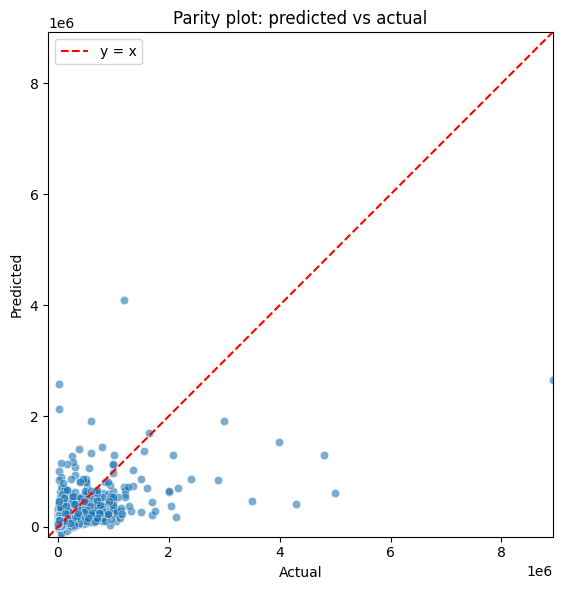

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
comparison = pd.DataFrame({
    "actual": df_test["montant_engage"],
    "pred": best_xgb_pred,
})

plt.figure(figsize=(6, 6))
sns.scatterplot(data=comparison, x="actual", y="pred", alpha=0.6)
lims = [comparison.values.min(), comparison.values.max()]
plt.plot(lims, lims, "r--", label="y = x")
plt.xlim(lims)
plt.ylim(lims)
plt.gca().set_aspect('equal', 'box')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Parity plot: predicted vs actual")
plt.legend()
plt.tight_layout()
plt.show()


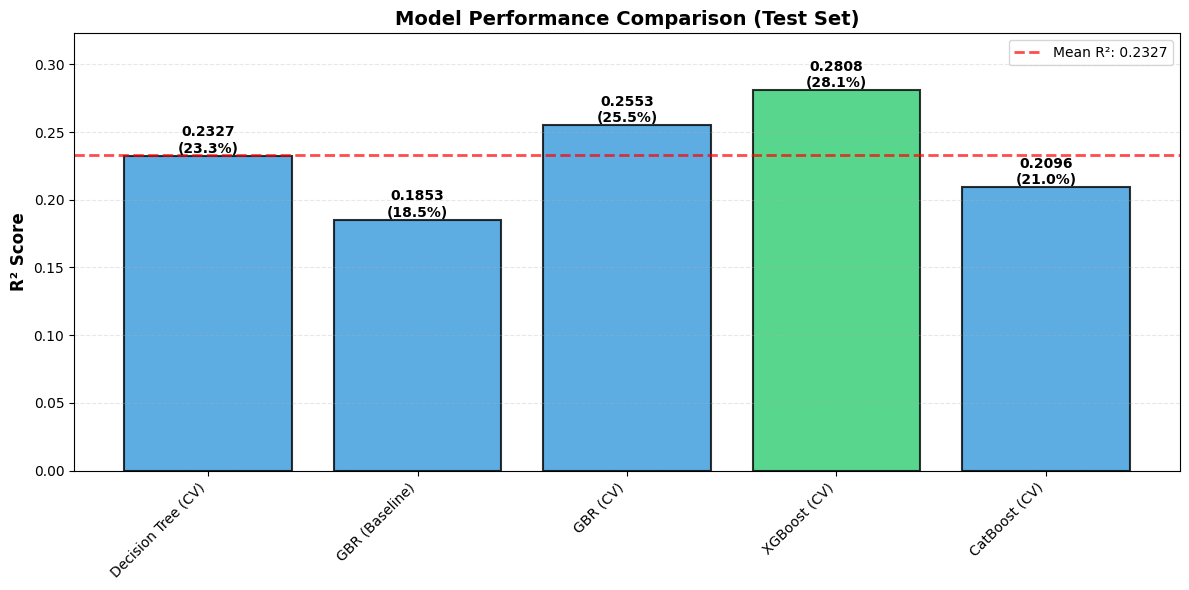


✓ Best Model: XGBoost (CV) with R² = 0.2808
  This model explains 28.1% of the variance in the test set


In [33]:
### Visualization: R² Score Comparison

import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for visualization
r2_data = {
    "Decision Tree (CV)": tree_r2,
    "GBR (Baseline)": gbr_baseline_r2,
    "GBR (CV)": gbr_r2,
    "XGBoost (CV)": xgb_r2,
    "CatBoost (CV)": cat_r2,
}

models = list(r2_data.keys())
scores = list(r2_data.values())

# Create bar plot
fig, ax = plt.subplots(figsize=(12, 6))
colors = ['#2ecc71' if s == max(scores) else '#3498db' for s in scores]
bars = ax.bar(models, scores, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bar, score in zip(bars, scores):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{score:.4f}\n({score*100:.1f}%)',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

# Add baseline reference line (mean)
mean_r2 = np.mean(scores)
ax.axhline(y=mean_r2, color='red', linestyle='--', linewidth=2, label=f'Mean R²: {mean_r2:.4f}', alpha=0.7)

# Formatting
ax.set_ylabel('R² Score', fontsize=12, fontweight='bold')
ax.set_title('Model Performance Comparison (Test Set)', fontsize=14, fontweight='bold')
ax.set_ylim(0, max(scores) * 1.15)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.legend(fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(f"\n✓ Best Model: {models[np.argmax(scores)]} with R² = {max(scores):.4f}")
print(f"  This model explains {max(scores)*100:.1f}% of the variance in the test set")
